#  Blood Donation Dataset — Data Cleaning & Exploratory Data Analysis


In [1]:
import warnings, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 100, 'figure.figsize': (8, 4.5), 'axes.titleweight': 'bold'})
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

## Load & first look

In [2]:
# The default reader turns the literal text "None" (Medical_Condition = no condition) into NaN.
default_read = pd.read_csv('blood_donation.csv')
print('Missing Medical_Condition with default read :', default_read['Medical_Condition'].isna().sum())

# "None" is a real category here (donor has no medical condition), so we keep it as text.
raw = pd.read_csv('blood_donation.csv', keep_default_na=False)
df = raw.copy()
print('Missing Medical_Condition with keep_default_na=False :', (raw['Medical_Condition'] == '').sum())
print('Shape:', df.shape)

Missing Medical_Condition with default read : 0
Missing Medical_Condition with keep_default_na=False : 0
Shape: (10000, 19)


In [3]:
df.head()

,Unnamed: 0,Donor_ID,Full_Name,Gender,Age,Blood_Group,Contact_Number,Email,City,State,Country,Last_Donation_Date,Total_Donations,Eligible_for_Donation,Medical_Condition,Weight_kg,Hemoglobin_g_dL,Donation_Center,Registration_Date
0,1,DNR000002,Meena Iyer,Female,49,B+,265423420,meena.iyer6225@gmail.com,Jaipur,Rajasthan,India,08-11-2020,1,No,Hypertension,70.8,14.0,Metro Blood Bank,03-03-2023
1,2,DNR000003,Priya Nair,Female,29,B+,1849593012,priya.nair4742@gmail.com,Gurgaon,Haryana,India,12-04-2025,2,No,Diabetes,73.4,12.5,Fortis Blood Bank,15-10-2015
2,6,DNR000007,Sangeeta Singh,Female,23,B+,4514626957,sangeeta.singh2928@gmail.com,Patna,Bihar,India,18-08-2024,3,No,Diabetes,66.4,12.5,Government Blood Bank,21-05-2019
3,7,DNR000008,Anil Patel,Male,33,B+,8809570063,anil.patel3924@gmail.com,Hyderabad,Telangana,India,28-06-2025,6,No,Diabetes,54.7,14.7,Fortis Blood Bank,19-04-2017
4,8,DNR000009,Asha Bose,Female,32,A+,2278248872,asha.bose8836@gmail.com,Patna,Bihar,India,13-08-2025,2,No,Hypertension,65.0,11.5,Fortis Blood Bank,09-12-2024


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             10000 non-null  int64  
 1   Donor_ID               10000 non-null  str    
 2   Full_Name              10000 non-null  str    
 3   Gender                 10000 non-null  str    
 4   Age                    10000 non-null  int64  
 5   Blood_Group            10000 non-null  str    
 6   Contact_Number         10000 non-null  int64  
 7   Email                  10000 non-null  str    
 8   City                   10000 non-null  str    
 9   State                  10000 non-null  str    
 10  Country                10000 non-null  str    
 11  Last_Donation_Date     10000 non-null  str    
 12  Total_Donations        10000 non-null  int64  
 13  Eligible_for_Donation  10000 non-null  str    
 14  Medical_Condition      10000 non-null  str    
 15  Weight_kg     

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,10000.0,4.999500e+03,2.886896e+03,0.0,2.499750e+03,4.999500e+03,7.499250e+03,9.999000e+03
Age,10000.0,3.389780e+01,9.417071e+00,18.0,2.700000e+01,3.400000e+01,4.000000e+01,6.500000e+01
Contact_Number,10000.0,5.028221e+09,2.876037e+09,363900.0,2.538943e+09,5.060247e+09,7.494996e+09,9.998636e+09
Total_Donations,10000.0,2.084800e+00,1.324003e+00,0.0,1.000000e+00,2.000000e+00,3.000000e+00,9.000000e+00
Weight_kg,10000.0,6.801556e+01,1.001426e+01,45.0,6.110000e+01,6.790000e+01,7.490000e+01,1.100000e+02
Hemoglobin_g_dL,10000.0,1.373798e+01,1.266010e+00,10.0,1.280000e+01,1.370000e+01,1.460000e+01,1.800000e+01


##  Data-quality audit
Before changing anything, check for blanks, whitespace, duplicates and constant columns.

In [6]:
as_str = raw.astype(str)
audit = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'n_unique': raw.nunique(),
    'blank_values': as_str.apply(lambda s: (s.str.strip() == '')).sum(),
    'whitespace_issues': as_str.apply(lambda s: (s != s.str.strip())).sum(),
})
display_audit = audit
print('Fully duplicated rows :', raw.duplicated().sum())
print('Duplicated Donor_IDs  :', raw['Donor_ID'].duplicated().sum())
display_audit

Fully duplicated rows : 0
Duplicated Donor_IDs  : 0


,dtype,n_unique,blank_values,whitespace_issues
Unnamed: 0,int64,10000,0,0
Donor_ID,str,10000,0,0
Full_Name,str,512,0,0
Gender,str,3,0,0
Age,int64,48,0,0
Blood_Group,str,8,0,0
Contact_Number,int64,10000,0,0
Email,str,9987,0,0
City,str,20,0,0
State,str,15,0,0


**Audit takeaways:** no blank cells, no whitespace problems and no duplicate rows. `Country` is constant (India), `Last_Donation_Date` contains the text `"Never"`, and dates / phone numbers are stored in the wrong data type. Cleaning therefore focuses on **type conversion, validation and feature creation** rather than imputation.

##  Column-by-column cleaning
Each column gets its own cell: *check → fix → validate*. Original columns are kept; derived columns are added next to them.

###  `Donor_ID`

In [7]:
print('Unique      :', df['Donor_ID'].is_unique)
print('Format ok   :', df['Donor_ID'].str.match(r'^DNR\d{6}$').all())
print('Sequential  :', df['Donor_ID'].is_monotonic_increasing)
df['Donor_ID'] = df['Donor_ID'].str.strip().str.upper()

Unique      : True
Format ok   : True
Sequential  : False


`Donor_ID` is a clean, unique primary key (`DNR000001` … `DNR010000`). No change needed beyond defensive trimming.

###  `Full_Name`

In [8]:
df['Full_Name'] = df['Full_Name'].str.strip().str.replace(r'\s+', ' ', regex=True).str.title()
names = df['Full_Name'].str.split(' ', n=1, expand=True)
df['First_Name'], df['Last_Name'] = names[0], names[1]

print(f"{df['Full_Name'].nunique()} unique names across {len(df):,} donors")
print('Names with only one word:', df['Last_Name'].isna().sum())
df['Full_Name'].value_counts().head(5)

512 unique names across 10,000 donors
Names with only one word: 0


Full_Name
Akash Verma     34
Sanjay Singh    34
Sanjay Naidu    32
Neha Bhat       32
Sonia Iyer      31
Name: count, dtype: int64

Names were standardised to Title Case and split into first / last name. Only ~500 distinct names exist for 10,000 donors, so **name is *not* an identifier** — always use `Donor_ID`.

###  `Gender`

In [9]:
df['Gender'] = df['Gender'].str.strip().str.title().astype('category')
df['Gender'].value_counts(dropna=False).to_frame('count').assign(pct=lambda x: (x['count'] / len(df) * 100).round(2))

,count,pct
Gender,,
Female,4986,49.86
Male,4906,49.06
Other,108,1.08


Three clean categories (Female / Male / Other). `Other` is small (~1%), so any statistics for it carry wide uncertainty.

###  `Age`

In [10]:
print(df['Age'].describe())
print('Outside legal donor range 18-65:', (~df['Age'].between(18, 65)).sum())
df['Age_Group'] = pd.cut(df['Age'], bins=[17, 25, 35, 45, 55, 65],
                         labels=['18-25', '26-35', '36-45', '46-55', '56-65'])
df['Age_Group'].value_counts().sort_index()

count    10000.000000
mean        33.897800
std          9.417071
min         18.000000
25%         27.000000
50%         34.000000
75%         40.000000
max         65.000000
Name: Age, dtype: float64
Outside legal donor range 18-65: 0


Age_Group
18-25    2079
26-35    3645
36-45    3123
46-55    1031
56-65     122
Name: count, dtype: int64

All ages fall in the 18–65 donor window, so no corrections were required. An `Age_Group` feature was added for segmentation.

### `Blood_Group`

In [11]:
df['Blood_Group'] = df['Blood_Group'].str.strip().str.upper()
valid = {'A+', 'A-', 'B+', 'B-', 'AB+', 'AB-', 'O+', 'O-'}
print('Invalid blood groups:', (~df['Blood_Group'].isin(valid)).sum())

df['ABO_Type'] = df['Blood_Group'].str[:-1]
df['Rh_Factor'] = np.where(df['Blood_Group'].str.endswith('+'), 'Positive', 'Negative')
df['Blood_Group'] = pd.Categorical(df['Blood_Group'], categories=['O+', 'O-', 'A+', 'A-', 'B+', 'B-', 'AB+', 'AB-'])
df['Blood_Group'].value_counts()

Invalid blood groups: 0


Blood_Group
O+     3729
B+     3136
A+     1842
O-      419
AB+     371
A-      208
B-      194
AB-     101
Name: count, dtype: int64

All 8 valid groups are present. Split into `ABO_Type` and `Rh_Factor` to analyse the antigen and Rh components independently.

###  `Contact_Number`

In [12]:

df['Contact_Number'] = df['Contact_Number'].astype(str).str.strip()
df['Contact_Digits'] = df['Contact_Number'].str.len()


df['Contact_Valid'] = df['Contact_Number'].str.match(r'^[6-9]\d{9}$')

print(df['Contact_Digits'].value_counts().sort_index().to_string())
print(f"\nValid Indian mobile format: {df['Contact_Valid'].mean():.1%}")
print('Duplicate phone numbers :', df['Contact_Number'].duplicated().sum())

Contact_Digits
6        2
7        8
8       93
9      865
10    9032

Valid Indian mobile format: 40.4%
Duplicate phone numbers : 0


Only a minority of numbers are valid Indian mobile numbers (10 digits starting with 6–9). The rest start with 1–5 or are shorter than 10 digits (some may have lost a leading digit when stored as numbers). Numbers were **kept but flagged** (`Contact_Valid`) rather than deleted, because we can't know the true value.

###  `Email`

In [13]:
df['Email'] = df['Email'].str.strip().str.lower()
df['Email_Valid'] = df['Email'].str.match(r'^[\w.+-]+@[\w-]+\.[\w.]+$')
df['Email_Duplicated'] = df['Email'].duplicated(keep=False)
df['Email_Domain'] = df['Email'].str.split('@').str[1]

print('Invalid format  :', (~df['Email_Valid']).sum())
print('Rows sharing an email:', df['Email_Duplicated'].sum())
print(df['Email_Domain'].value_counts().to_string())
df.loc[df['Email_Duplicated'], ['Donor_ID', 'Full_Name', 'Email', 'City', 'Age']].sort_values('Email').head(6)

Invalid format  : 0
Rows sharing an email: 26
Email_Domain
gmail.com    10000


,Donor_ID,Full_Name,Email,City,Age
222,DNR000662,Akash Joshi,akash.joshi8695@gmail.com,Chennai,42
8801,DNR008114,Akash Joshi,akash.joshi8695@gmail.com,Chennai,37
824,DNR002368,Asha Singh,asha.singh7131@gmail.com,Thiruvananthapuram,47
4778,DNR001856,Asha Singh,asha.singh7131@gmail.com,Delhi,50
8404,DNR007451,Kavita Iyer,kavita.iyer3650@gmail.com,Nagpur,31
8912,DNR008274,Kavita Iyer,kavita.iyer3650@gmail.com,Vadodara,38


Every email has valid syntax and uses `gmail.com`. 13 addresses are shared by two donors; they are different people (different city/age) who collided on the generated `name + number` pattern, so they are flagged but not removed.

###  `City`, `State`, `Country`

In [14]:
for c in ['City', 'State', 'Country']:
    df[c] = df[c].str.strip().str.title()


print('Cities mapped to >1 state:', (df.groupby('City')['State'].nunique() > 1).sum())
print('Countries:', df['Country'].unique())
df.groupby(['State', 'City']).size().rename('donors').reset_index().head(20)

Cities mapped to >1 state: 0
Countries: <ArrowStringArray>
['India']
Length: 1, dtype: str


,State,City,donors
0,Andhra Pradesh,Visakhapatnam,495
1,Bihar,Patna,519
2,Delhi,Delhi,511
3,Gujarat,Ahmedabad,494
4,Gujarat,Surat,503
5,Gujarat,Vadodara,455
6,Haryana,Gurgaon,504
7,Karnataka,Bengaluru,507
8,Kerala,Thiruvananthapuram,490
9,Madhya Pradesh,Bhopal,484


City → State mapping is consistent (20 cities, 15 states). `Country` is always *India* — a constant column with no analytical value, so it is excluded from the analysis.

###  `Last_Donation_Date`, `Total_Donations` and `Registration_Date`

In [15]:

ld = df['Last_Donation_Date'].str.strip()
df['Ever_Donated'] = ld.str.lower() != 'never'
df['Last_Donation_Date'] = pd.to_datetime(ld.where(df['Ever_Donated']), format='%d-%m-%Y', errors='coerce')
df['Registration_Date'] = pd.to_datetime(df['Registration_Date'].str.strip(), format='%d-%m-%Y', errors='coerce')

print('Unparseable registration dates:', df['Registration_Date'].isna().sum())
print('Last donation range :', df['Last_Donation_Date'].min().date(), '→', df['Last_Donation_Date'].max().date())
print('Registration range  :', df['Registration_Date'].min().date(), '→', df['Registration_Date'].max().date())


REF_DATE = df['Last_Donation_Date'].max()
df['Days_Since_Last_Donation'] = (REF_DATE - df['Last_Donation_Date']).dt.days
df['Registration_Year'] = df['Registration_Date'].dt.year
df['Tenure_Years'] = ((REF_DATE - df['Registration_Date']).dt.days / 365.25).round(2)
print('Reference date used:', REF_DATE.date())

Unparseable registration dates: 0
Last donation range : 2020-11-08 → 2025-11-07
Registration range  : 2008-02-29 → 2025-11-06
Reference date used: 2025-11-07


In [16]:

print('Total_Donations range:', df['Total_Donations'].min(), '-', df['Total_Donations'].max())
print(pd.crosstab(df['Total_Donations'] == 0, df['Ever_Donated'],
                  rownames=['Total_Donations == 0'], colnames=['Has a last-donation date']))


df['Donated_Before_Registration'] = df['Last_Donation_Date'] < df['Registration_Date']
print('\nLast donation BEFORE registration:', df['Donated_Before_Registration'].sum(),
      f"({df['Donated_Before_Registration'].sum() / df['Ever_Donated'].sum():.1%} of donors who donated)")

Total_Donations range: 0 - 9
Has a last-donation date  False  True 
Total_Donations == 0                  
False                         0   9424
True                        576      0

Last donation BEFORE registration: 358 (3.8% of donors who donated)


* `"Never"` was converted to a missing date and captured in `Ever_Donated`; the 576 'Never' donors are exactly those with `Total_Donations = 0` (fully consistent).
* **Logical inconsistency found:** about 4% of donors have a last donation date earlier than their registration date. These rows are **flagged** (`Donated_Before_Registration`), not deleted – they may be donations made before they were entered in this system.
* Added `Days_Since_Last_Donation`, `Registration_Year` and `Tenure_Years` features.

###  `Eligible_for_Donation`

In [17]:
df['Eligible_for_Donation'] = df['Eligible_for_Donation'].str.strip().str.title()
print(df['Eligible_for_Donation'].value_counts().to_string())
df['Is_Eligible'] = df['Eligible_for_Donation'].map({'Yes': 1, 'No': 0}).astype(int)

Eligible_for_Donation
Yes    6416
No     3584


Binary Yes/No converted into a 0/1 target-style column `Is_Eligible` (kept alongside the original text).

###  `Medical_Condition`

In [18]:

print('Blank / whitespace-padded values:', (df['Medical_Condition'].str.strip() == '').sum(), '/', (df['Medical_Condition'] != df['Medical_Condition'].str.strip()).sum())
print(df['Medical_Condition'].value_counts().to_string())
print(f"\nDonors with any condition: {(df['Medical_Condition'] != 'None').mean():.1%}")

Blank / whitespace-padded values: 0 / 0
Medical_Condition
Healthy                 6416
Hypertension            2003
Anemia                   469
Diabetes                 388
Asthma                   308
Recent Surgery           207
Infection (resolved)     109
Cardiac issues           100

Donors with any condition: 100.0%


**This column was not modified.** `None` is a valid category (no condition), **not** missing data; the 7 conditions are already consistent, so no cleaning was needed.

### `Weight_kg` and `Hemoglobin_g_dL` — range & outlier check

In [19]:
def iqr_flag(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)


for col in ['Weight_kg', 'Hemoglobin_g_dL']:
    print(f"{col:16s} min={df[col].min():6.1f}  max={df[col].max():6.1f}  "
          f"IQR-outliers={iqr_flag(df[col]).sum()}")

print('\nWeight below the 50 kg donation minimum :', (df['Weight_kg'] < 50).sum())
print('Hemoglobin below 12.5 g/dL              :', (df['Hemoglobin_g_dL'] < 12.5).sum())
print('Hemoglobin pile-up at limits (10.0 / 18.0):', (df['Hemoglobin_g_dL'] == 10).sum(), '/', (df['Hemoglobin_g_dL'] == 18).sum())
print('Weight pile-up at limits (45 / 110)       :', (df['Weight_kg'] == 45).sum(), '/', (df['Weight_kg'] == 110).sum())

Weight_kg        min=  45.0  max= 110.0  IQR-outliers=27
Hemoglobin_g_dL  min=  10.0  max=  18.0  IQR-outliers=28

Weight below the 50 kg donation minimum : 363
Hemoglobin below 12.5 g/dL              : 1594
Hemoglobin pile-up at limits (10.0 / 18.0): 12 / 1
Weight pile-up at limits (45 / 110)       : 107 / 1


Values are physiologically plausible (weight 45–110 kg, haemoglobin 10–18 g/dL), so **both columns were left unchanged**: the outliers are real extremes, not errors. Weight shows a small pile-up at its lower limit (45 kg) and haemoglobin at 10.0 — typical of values clipped by the data generator, worth remembering when reading the tails.

###  `Donation_Center`

In [20]:
df['Donation_Center'] = df['Donation_Center'].str.strip().str.title().str.replace('Nabl', 'NABL')
df['Donation_Center'].value_counts()

Donation_Center
Corporate Health Centre        1039
Red Cross Blood Bank           1033
NABL Blood Centre              1032
Private Diagnostic Centre      1030
City Blood Centre              1003
Metro Blood Bank               1000
Apollo Hospitals Blood Bank     973
Fortis Blood Bank               971
Government Blood Bank           968
Community Blood Bank            951
Name: count, dtype: int64

Ten centres with near-equal volume (≈ 950–1,040 donors each). No spelling variants found.

###  Final cleaned dataset

In [21]:
for c in ['State', 'City', 'Donation_Center', 'Eligible_for_Donation', 'ABO_Type', 'Rh_Factor']:
    df[c] = df[c].astype('category')

df_clean = df.drop(columns=['Country'])        # constant column
df_clean.to_csv('blood_donation_clean.csv', index=False)

print('Raw shape  :', raw.shape)
print('Clean shape:', df_clean.shape)
print('Missing values left (only the intentional NaT for "Never" donors):')
print(df_clean.isna().sum()[lambda s: s > 0].to_string())
df_clean.dtypes.to_frame('dtype').T

Raw shape  : (10000, 19)
Clean shape: (10000, 34)
Missing values left (only the intentional NaT for "Never" donors):
Last_Donation_Date          576
Days_Since_Last_Donation    576


,Unnamed: 0,Donor_ID,Full_Name,Gender,Age,Blood_Group,Contact_Number,Email,City,State,Last_Donation_Date,Total_Donations,Eligible_for_Donation,Medical_Condition,Weight_kg,Hemoglobin_g_dL,Donation_Center,Registration_Date,First_Name,Last_Name,Age_Group,ABO_Type,Rh_Factor,Contact_Digits,Contact_Valid,Email_Valid,Email_Duplicated,Email_Domain,Ever_Donated,Days_Since_Last_Donation,Registration_Year,Tenure_Years,Donated_Before_Registration,Is_Eligible
dtype,int64,str,str,category,int64,category,str,str,category,category,datetime64[us],int64,category,str,float64,float64,category,datetime64[us],str,str,category,category,category,int64,bool,bool,bool,object,bool,float64,int32,float64,bool,int64


In [36]:
df_clean

,Unnamed: 0,Donor_ID,Full_Name,Gender,Age,Blood_Group,Contact_Number,Email,City,State,Last_Donation_Date,Total_Donations,Eligible_for_Donation,Medical_Condition,Weight_kg,Hemoglobin_g_dL,Donation_Center,Registration_Date,First_Name,Last_Name,Age_Group,ABO_Type,Rh_Factor,Contact_Digits,Contact_Valid,Email_Valid,Email_Duplicated,Email_Domain,Ever_Donated,Days_Since_Last_Donation,Registration_Year,Tenure_Years,Donated_Before_Registration,Is_Eligible
0,1,DNR000002,Meena Iyer,Female,49,B+,265423420,meena.iyer6225@gmail.com,Jaipur,Rajasthan,2020-11-08,1,No,Hypertension,70.8,14.0,Metro Blood Bank,2023-03-03,Meena,Iyer,46-55,B,Positive,9,False,True,False,gmail.com,True,1825.0,2023,2.68,True,0
1,2,DNR000003,Priya Nair,Female,29,B+,1849593012,priya.nair4742@gmail.com,Gurgaon,Haryana,2025-04-12,2,No,Diabetes,73.4,12.5,Fortis Blood Bank,2015-10-15,Priya,Nair,26-35,B,Positive,10,False,True,False,gmail.com,True,209.0,2015,10.06,False,0
2,6,DNR000007,Sangeeta Singh,Female,23,B+,4514626957,sangeeta.singh2928@gmail.com,Patna,Bihar,2024-08-18,3,No,Diabetes,66.4,12.5,Government Blood Bank,2019-05-21,Sangeeta,Singh,18-25,B,Positive,10,False,True,False,gmail.com,True,446.0,2019,6.47,False,0
3,7,DNR000008,Anil Patel,Male,33,B+,8809570063,anil.patel3924@gmail.com,Hyderabad,Telangana,2025-06-28,6,No,Diabetes,54.7,14.7,Fortis Blood Bank,2017-04-19,Anil,Patel,26-35,B,Positive,10,True,True,False,gmail.com,True,132.0,2017,8.55,False,0
4,8,DNR000009,Asha Bose,Female,32,A+,2278248872,asha.bose8836@gmail.com,Patna,Bihar,2025-08-13,2,No,Hypertension,65.0,11.5,Fortis Blood Bank,2024-12-09,Asha,Bose,26-35,A,Positive,10,False,True,False,gmail.com,True,86.0,2024,0.91,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9993,DNR009994,Amit Naidu,Male,33,O+,4863037005,amit.naidu4388@gmail.com,Surat,Gujarat,2024-11-10,1,Yes,Healthy,69.7,13.7,Corporate Health Centre,2022-11-06,Amit,Naidu,26-35,O,Positive,10,False,True,False,gmail.com,True,362.0,2022,3.00,False,1
9996,9995,DNR009996,Anjali Naidu,Female,33,O+,6657949468,anjali.naidu1428@gmail.com,Bengaluru,Karnataka,2023-11-30,1,Yes,Healthy,74.6,14.2,Apollo Hospitals Blood Bank,2015-05-29,Anjali,Naidu,26-35,O,Positive,10,True,True,False,gmail.com,True,708.0,2015,10.44,False,1
9997,9997,DNR009998,Nisha Iyer,Female,39,O+,4183958332,nisha.iyer1956@gmail.com,Kolkata,West Bengal,2025-07-12,2,Yes,Healthy,70.5,13.3,Apollo Hospitals Blood Bank,2016-04-16,Nisha,Iyer,36-45,O,Positive,10,False,True,False,gmail.com,True,118.0,2016,9.56,False,1
9998,9998,DNR009999,Siddharth Menon,Male,35,B+,3105927220,siddharth.menon6401@gmail.com,Vadodara,Gujarat,2021-11-09,1,Yes,Healthy,66.4,14.9,Government Blood Bank,2020-05-24,Siddharth,Menon,26-35,B,Positive,10,False,True,False,gmail.com,True,1459.0,2020,5.46,False,1


**Cleaning summary**

| Column | Issue | Action |
|---|---|---|
| Medical_Condition | `"None"` read as NaN by default | **Unchanged** – read with `keep_default_na=False` |
| Contact_Number | Stored as integer, many invalid numbers | Converted to text, `Contact_Valid` flag |
| Email | 13 shared addresses | `Email_Duplicated` flag, `Email_Domain` |
| Last_Donation_Date | `"Never"` text, wrong dtype | Parsed to datetime, `Ever_Donated`, `Days_Since_Last_Donation` |
| Registration_Date | wrong dtype | Parsed, `Registration_Year`, `Tenure_Years` |
| Last vs Registration date | ~4% donated before registering | `Donated_Before_Registration` flag |
| Weight / Hemoglobin | Plausible but with extremes | **Unchanged** (checked only) |
| Country | Constant | Dropped |
| Age, Blood_Group, Gender, City, State, Center | Clean | Types set, `Age_Group`, `ABO_Type`, `Rh_Factor` added |

##  Exploratory Data Analysis
###  Numeric variables — distributions

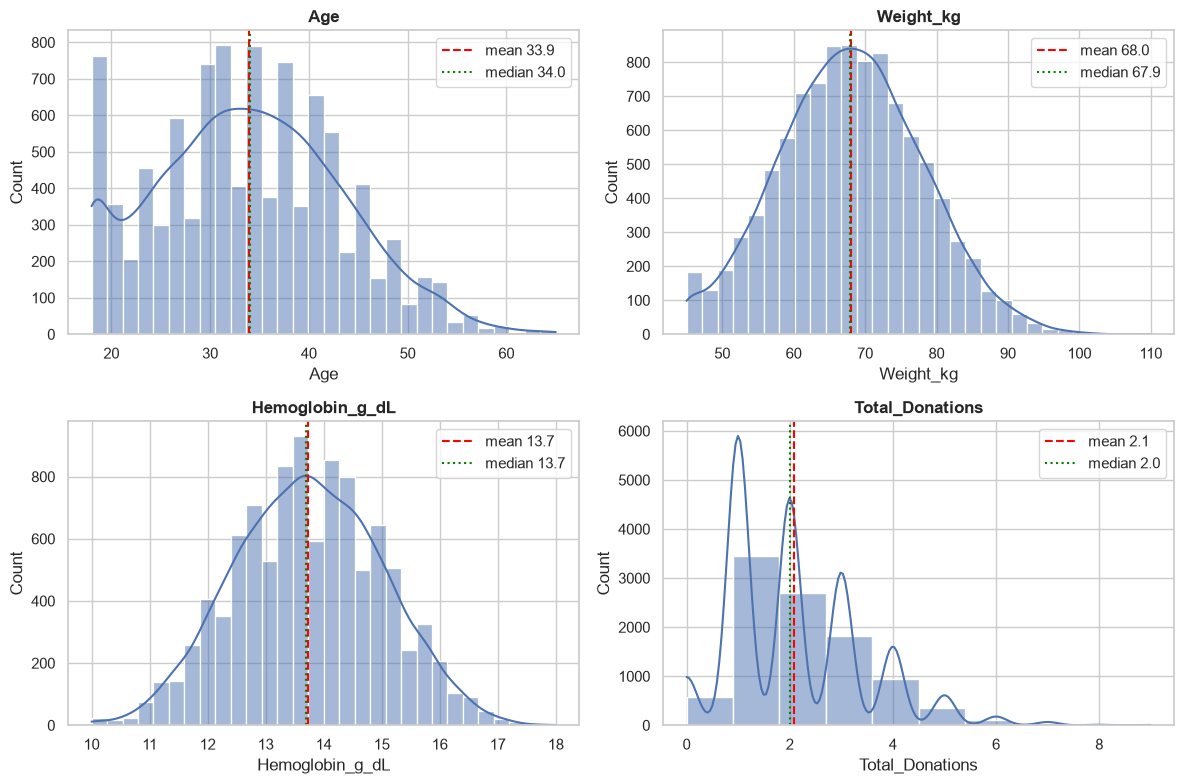

,skew,kurtosis
Age,0.23,-0.42
Weight_kg,0.09,-0.20
Hemoglobin_g_dL,0.00,-0.31
Total_Donations,0.89,0.88


In [22]:
num_cols = ['Age', 'Weight_kg', 'Hemoglobin_g_dL', 'Total_Donations']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df_clean[c], kde=True, ax=ax, bins=30 if c != 'Total_Donations' else 10)
    ax.axvline(df_clean[c].mean(), color='red', ls='--', label=f"mean {df_clean[c].mean():.1f}")
    ax.axvline(df_clean[c].median(), color='green', ls=':', label=f"median {df_clean[c].median():.1f}")
    ax.set_title(c); ax.legend()
plt.tight_layout(); plt.show()

pd.DataFrame({'skew': df_clean[num_cols].skew(), 'kurtosis': df_clean[num_cols].kurt()}).round(2)

* **Age** – centred around 34, slightly right-skewed; most donors are 25–40.
* **Weight** – roughly symmetric around 68 kg.
* **Haemoglobin** – roughly normal around 13.7 g/dL.
* **Total donations** – right-skewed: most donors gave 1–3 times, very few exceed 5.

### Categorical variables

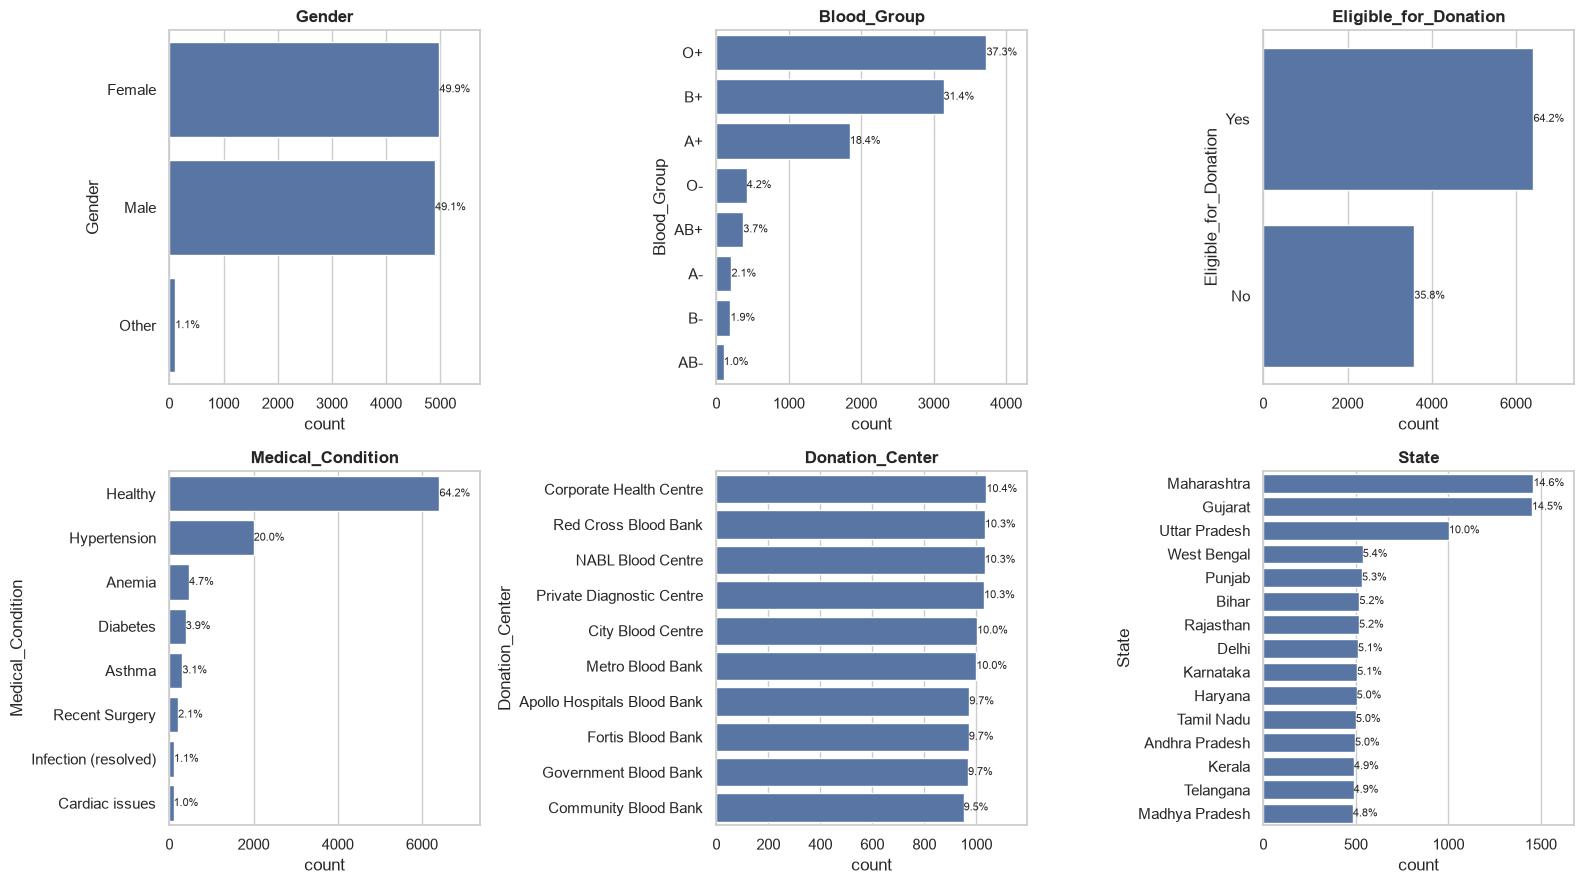

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
order = lambda c: df_clean[c].value_counts().index
for ax, c in zip(axes.ravel(), ['Gender', 'Blood_Group', 'Eligible_for_Donation', 'Medical_Condition', 'Donation_Center', 'State']):
    sns.countplot(data=df_clean, y=c, order=order(c), ax=ax)
    ax.set_title(c)
    for p in ax.patches:
        ax.annotate(f"{p.get_width() / len(df_clean):.1%}", (p.get_width(), p.get_y() + p.get_height() / 2),
                    va='center', ha='left', fontsize=8)
    ax.margins(x=0.15)
plt.tight_layout(); plt.show()

* Gender is balanced between Female (≈ 50%) and Male (≈ 49%); `Other` ≈ 1%.
* **O+ and B+ dominate** (≈ 37% and 31%); the Rh-negative groups are rare.
* About **64% of donors are eligible**, and **78% report no medical condition**.
* Donation centres are evenly sized (≈ 9.5–10.4% each). State shares differ only because Maharashtra, Gujarat and Uttar Pradesh contain 3, 3 and 2 cities; **every city has about the same number of donors** (≈ 450–540), which looks synthetic/uniformly sampled.

###  Blood-group composition

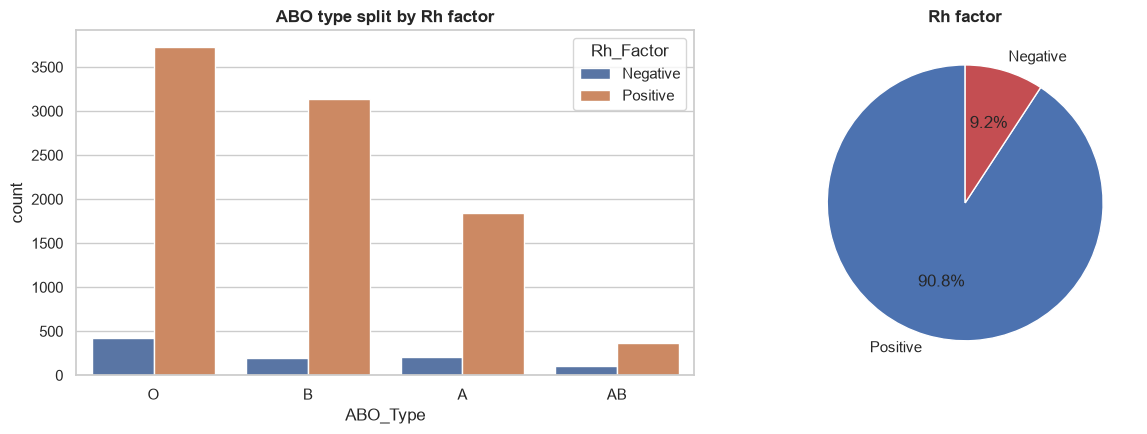

,donors,pct
Blood_Group,,
O+,3729,37.29
B+,3136,31.36
A+,1842,18.42
O-,419,4.19
AB+,371,3.71
A-,208,2.08
B-,194,1.94
AB-,101,1.01


In [24]:
bg = df_clean['Blood_Group'].value_counts().to_frame('donors')
bg['pct'] = (bg['donors'] / len(df_clean) * 100).round(2)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df_clean, x='ABO_Type', hue='Rh_Factor', order=['O', 'B', 'A', 'AB'], ax=ax[0])
ax[0].set_title('ABO type split by Rh factor')
rh = df_clean['Rh_Factor'].value_counts()
ax[1].pie(rh, labels=rh.index, autopct='%1.1f%%', startangle=90, colors=['#4c72b0', '#c44e52'])
ax[1].set_title('Rh factor')
plt.tight_layout(); plt.show()
bg

Rh-negative donors form only ~9% of the base; AB- is the scarcest group (≈ 1%). O- (the universal donor group) is just ~4%.

###  Geography & donation centres

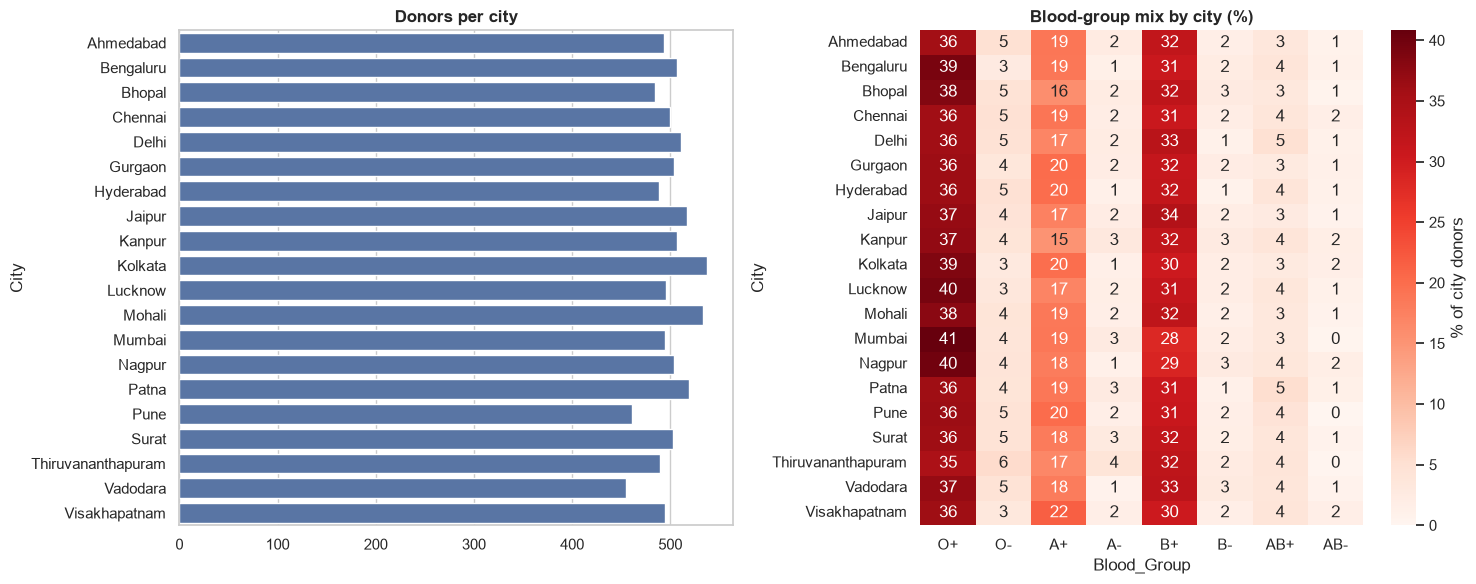

Chi-square (City x Blood group): p = 0.837  -> no significant difference between cities


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
city_counts = df_clean['City'].value_counts()
sns.barplot(x=city_counts.values, y=city_counts.index, ax=ax[0], color='#4c72b0')
ax[0].set_title('Donors per city')

heat = pd.crosstab(df_clean['City'], df_clean['Blood_Group'], normalize='index') * 100
sns.heatmap(heat, annot=True, fmt='.0f', cmap='Reds', ax=ax[1], cbar_kws={'label': '% of city donors'})
ax[1].set_title('Blood-group mix by city (%)')
plt.tight_layout(); plt.show()

chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df_clean['City'], df_clean['Blood_Group']))
print(f'Chi-square (City x Blood group): p = {p:.3f}  ->',
      'significant difference' if p < 0.05 else 'no significant difference between cities')

Every city contributes ~450–540 donors and the blood-group mix is the same everywhere (chi-square not significant). Geography is therefore **not** a driver of blood type in this dataset.

###  Time analysis — registrations and donations

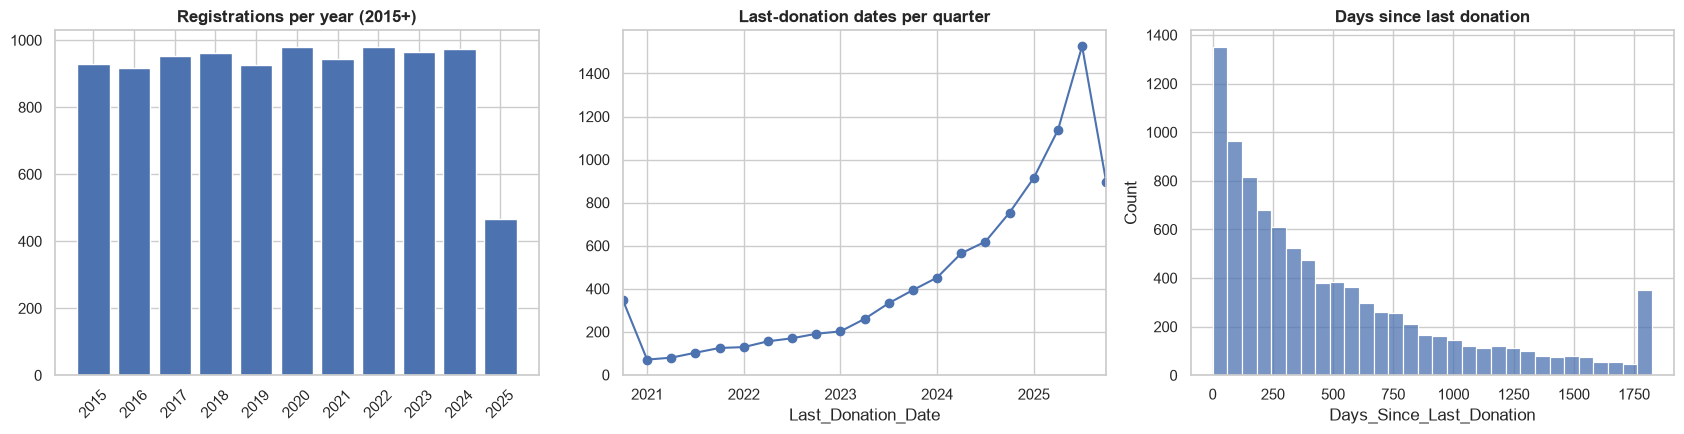

Only 2 donors registered before 2015
Last donated within 90 days : 19.9%
Last donated within 1 year  : 52.5%
Last donated > 2 years ago  : 24.6%


In [26]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
reg = df_clean['Registration_Year'].value_counts().sort_index()
reg = reg[reg.index >= 2015]
ax[0].bar(reg.index.astype(str), reg.values, color='#4c72b0'); ax[0].set_title('Registrations per year (2015+)')
ax[0].tick_params(axis='x', rotation=45)

ld = df_clean.dropna(subset=['Last_Donation_Date'])
by_month = ld.groupby(ld['Last_Donation_Date'].dt.to_period('Q')).size()
by_month.plot(ax=ax[1], marker='o'); ax[1].set_title('Last-donation dates per quarter')

sns.histplot(df_clean['Days_Since_Last_Donation'].dropna(), bins=30, ax=ax[2])
ax[2].set_title('Days since last donation')
plt.tight_layout(); plt.show()

print('Only', (df_clean['Registration_Year'] < 2015).sum(), 'donors registered before 2015')
s = df_clean['Days_Since_Last_Donation'].dropna()
print(f'Last donated within 90 days : {(s <= 90).mean():.1%}')
print(f'Last donated within 1 year  : {(s <= 365).mean():.1%}')
print(f'Last donated > 2 years ago  : {(s > 730).mean():.1%}')

Registrations are steady (~900–980 per year from 2015 on; 2025 covers only ~10 months). Last-donation dates are spread uniformly across the 5 years, so there is no seasonality. Many donors haven't donated for over a year – a large **lapsed-donor** population.

###  Medical conditions

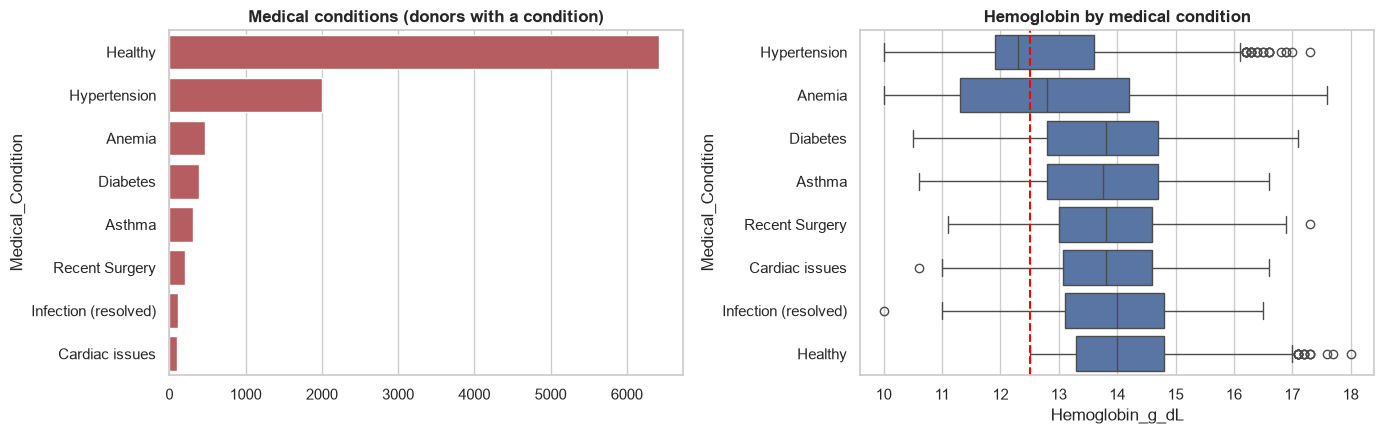

,count,mean,min,max
Medical_Condition,,,,
Hypertension,2003,12.76,10.0,17.3
Anemia,469,12.86,10.0,17.6
Diabetes,388,13.76,10.5,17.1
Asthma,308,13.80,10.6,16.6
Recent Surgery,207,13.81,11.1,17.3
Cardiac issues,100,13.84,10.6,16.6
Infection (resolved),109,13.84,10.0,16.5
Healthy,6416,14.10,12.5,18.0


In [27]:
cond = df_clean.loc[df_clean['Medical_Condition'] != 'None', 'Medical_Condition'].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=cond.values, y=cond.index.astype(str), ax=ax[0], color='#c44e52'); ax[0].set_title('Medical conditions (donors with a condition)')
sns.boxplot(data=df_clean, y='Medical_Condition', x='Hemoglobin_g_dL', ax=ax[1],
            order=df_clean.groupby('Medical_Condition')['Hemoglobin_g_dL'].mean().sort_values().index)
ax[1].set_title('Hemoglobin by medical condition'); ax[1].axvline(12.5, color='red', ls='--')
plt.tight_layout(); plt.show()
df_clean.groupby('Medical_Condition')['Hemoglobin_g_dL'].agg(['count', 'mean', 'min', 'max']).round(2).sort_values('mean')

Hypertension (≈ 6%) and anaemia (≈ 5%) are the most common conditions. As expected, **anaemic donors have clearly lower haemoglobin** (≈ 12.9 vs ≈ 13.8), while every other condition has the same average Hb as healthy donors.

###  What decides eligibility?

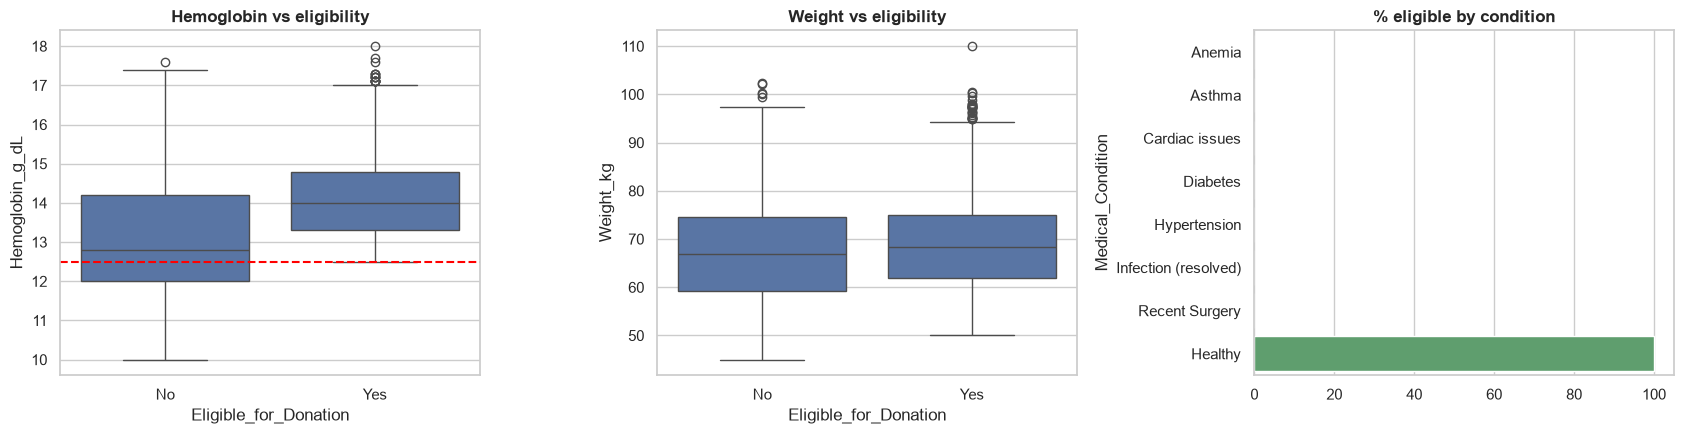

                         Age     Weight_kg       Hemoglobin_g_dL      
                        mean min      mean   min            mean   min
Eligible_for_Donation                                                 
No                     33.88  18     66.66  45.0           13.09  10.0
Yes                    33.91  18     68.77  50.0           14.10  12.5


In [28]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=df_clean, x='Eligible_for_Donation', y='Hemoglobin_g_dL', ax=ax[0]); ax[0].axhline(12.5, color='red', ls='--'); ax[0].set_title('Hemoglobin vs eligibility')
sns.boxplot(data=df_clean, x='Eligible_for_Donation', y='Weight_kg', ax=ax[1]); ax[1].set_title('Weight vs eligibility')
rate = df_clean.groupby('Medical_Condition')['Is_Eligible'].mean().sort_values() * 100
sns.barplot(x=rate.values, y=rate.index.astype(str), ax=ax[2], color='#55a868'); ax[2].set_title('% eligible by condition')
plt.tight_layout(); plt.show()

print(df_clean.groupby('Eligible_for_Donation')[['Age', 'Weight_kg', 'Hemoglobin_g_dL']].agg(['mean', 'min']).round(2))

In [29]:

has_condition = df_clean['Medical_Condition'] != 'None'
rule1 = (~has_condition) & (df_clean['Hemoglobin_g_dL'] >= 12.5)
print('Rule 1 (no condition & Hb >= 12.5) matches', f"{(rule1.astype(int) == df_clean['Is_Eligible']).mean():.1%}", 'of donors')
print(pd.crosstab(rule1, df_clean['Eligible_for_Donation'], rownames=['Rule 1 says eligible'], colnames=['Recorded']))

mis = df_clean[rule1 & (df_clean['Is_Eligible'] == 0)]
print('\nRule-1 eligible but recorded "No":', len(mis))
print('Their max weight:', mis['Weight_kg'].max(), '| min eligible weight overall:', df_clean.loc[df_clean['Is_Eligible'] == 1, 'Weight_kg'].min())


rule2 = rule1 & (df_clean['Weight_kg'] >= 50)
print('\nRule 2 (+ weight >= 50 kg) matches', f"{(rule2.astype(int) == df_clean['Is_Eligible']).mean():.1%}", 'of donors')
print(pd.crosstab(rule2, df_clean['Eligible_for_Donation'], rownames=['Rule 2 says eligible'], colnames=['Recorded']))

Rule 1 (no condition & Hb >= 12.5) matches 35.8% of donors
Recorded                No   Yes
Rule 1 says eligible            
False                 3584  6416

Rule-1 eligible but recorded "No": 0
Their max weight: nan | min eligible weight overall: 50.0

Rule 2 (+ weight >= 50 kg) matches 35.8% of donors
Recorded                No   Yes
Rule 2 says eligible            
False                 3584  6416


**Eligibility is fully rule-based.** A donor is recorded as eligible **if and only if all three conditions hold**:

1. no medical condition,
2. haemoglobin ≥ 12.5 g/dL, and
3. weight ≥ 50 kg.

Rule 1 alone explains 97.6% of the records; adding the 50 kg minimum weight reproduces `Eligible_for_Donation` for **100%** of donors. Age, blood group, centre, state and donation history play no role (see the checks below).

In [30]:
def elig_table(col):
    t = df_clean.groupby(col, observed=True)['Is_Eligible'].agg(['count', 'mean'])
    t['mean'] = (t['mean'] * 100).round(1)
    p = stats.chi2_contingency(pd.crosstab(df_clean[col], df_clean['Is_Eligible']))[1]
    return t.rename(columns={'mean': '% eligible'}), p

for c in ['Gender', 'Age_Group', 'Blood_Group', 'Donation_Center', 'State']:
    t, p = elig_table(c)
    print(f'--- {c}  (chi-square p = {p:.3f}) ---')
    print(t.to_string(), '\n')

--- Gender  (chi-square p = 0.000) ---
        count  % eligible
Gender                   
Female   4986        53.4
Male     4906        75.2
Other     108        59.3 

--- Age_Group  (chi-square p = 0.845) ---
           count  % eligible
Age_Group                   
18-25       2079        64.4
26-35       3645        63.8
36-45       3123        64.1
46-55       1031        64.3
56-65        122        68.9 

--- Blood_Group  (chi-square p = 0.071) ---
             count  % eligible
Blood_Group                   
O+            3729        62.7
O-             419        64.4
A+            1842        63.4
A-             208        69.7
B+            3136        65.1
B-             194        67.5
AB+            371        68.5
AB-            101        69.3 

--- Donation_Center  (chi-square p = 0.158) ---
                             count  % eligible
Donation_Center                               
Apollo Hospitals Blood Bank    973        64.7
City Blood Centre             1003   

Gender is the only demographic factor with a significant effect on eligibility (p < 0.001), and it works *through haemoglobin* (see 4.8). Age group, blood group, centre and state show no significant relationship.

###  Gender and haemoglobin

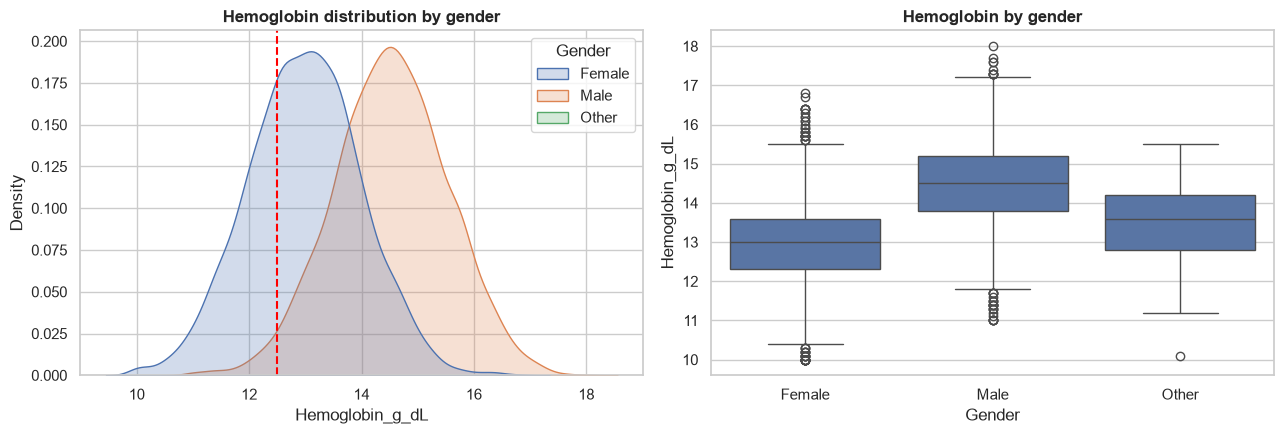

         mean   std
Gender             
Female  12.98  1.00
Male    14.52  1.01
Other   13.48  0.99

Welch t-test Female vs Male: t = -76.2, p = 0.00e+00, mean diff = -1.54 g/dL

% with Hb < 12.5 g/dL (deferral threshold):
Gender
Female    29.6
Male       2.1
Other     16.7


In [31]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.kdeplot(data=df_clean[df_clean['Gender'] != 'Other'], x='Hemoglobin_g_dL', hue='Gender', fill=True, ax=ax[0])
ax[0].axvline(12.5, color='red', ls='--'); ax[0].set_title('Hemoglobin distribution by gender')
sns.boxplot(data=df_clean, x='Gender', y='Hemoglobin_g_dL', ax=ax[1]); ax[1].set_title('Hemoglobin by gender')
plt.tight_layout(); plt.show()

print(df_clean.groupby('Gender', observed=True)['Hemoglobin_g_dL'].agg(['mean', 'std']).round(2))
f = df_clean.loc[df_clean['Gender'] == 'Female', 'Hemoglobin_g_dL']
m = df_clean.loc[df_clean['Gender'] == 'Male', 'Hemoglobin_g_dL']
t, p = stats.ttest_ind(f, m, equal_var=False)
print(f'\nWelch t-test Female vs Male: t = {t:.1f}, p = {p:.2e}, mean diff = {f.mean() - m.mean():.2f} g/dL')

low = df_clean.assign(low_hb=df_clean['Hemoglobin_g_dL'] < 12.5).groupby('Gender', observed=True)['low_hb'].mean() * 100
print('\n% with Hb < 12.5 g/dL (deferral threshold):'); print(low.round(1).to_string())

Women have haemoglobin ~1.5 g/dL lower than men (a highly significant difference). Because the Hb cut-off is the same for everyone, **women are far more likely to be deferred for low haemoglobin** — this is the main driver of the gender gap in eligibility.

###  Donation behaviour

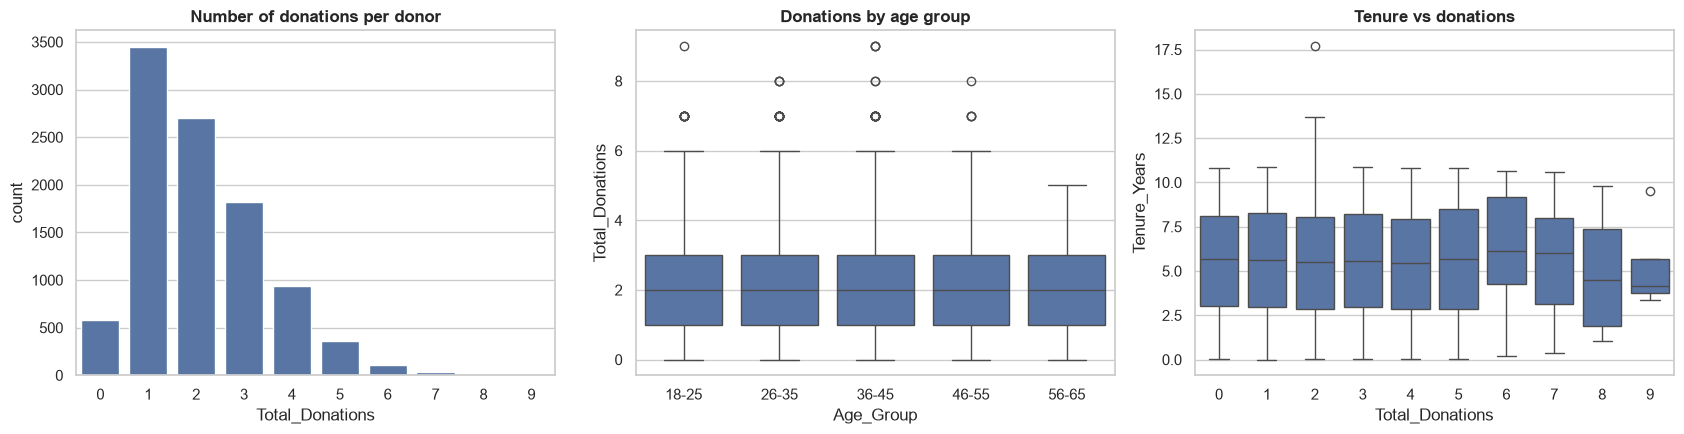

One-time or never donors (0-1 donations): 40.2%
Repeat donors (>= 3 donations)          : 32.7%
Regular donors (>= 5 donations)         : 5.1%
Spearman tenure vs donations: rho = -0.004, p = 0.68
Mean donations: eligible 2.08 | not eligible 2.1


In [32]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.countplot(data=df_clean, x='Total_Donations', ax=ax[0], color='#4c72b0'); ax[0].set_title('Number of donations per donor')
sns.boxplot(data=df_clean, x='Age_Group', y='Total_Donations', ax=ax[1]); ax[1].set_title('Donations by age group')
sns.boxplot(data=df_clean, x='Total_Donations', y='Tenure_Years', ax=ax[2]); ax[2].set_title('Tenure vs donations')
plt.tight_layout(); plt.show()

print(f"One-time or never donors (0-1 donations): {(df_clean['Total_Donations'] <= 1).mean():.1%}")
print(f"Repeat donors (>= 3 donations)          : {(df_clean['Total_Donations'] >= 3).mean():.1%}")
print(f"Regular donors (>= 5 donations)         : {(df_clean['Total_Donations'] >= 5).mean():.1%}")
rho, p = stats.spearmanr(df_clean['Tenure_Years'], df_clean['Total_Donations'])
print(f'Spearman tenure vs donations: rho = {rho:.3f}, p = {p:.2f}')
print('Mean donations: eligible', df_clean.loc[df_clean['Is_Eligible'] == 1, 'Total_Donations'].mean().round(2),
      '| not eligible', df_clean.loc[df_clean['Is_Eligible'] == 0, 'Total_Donations'].mean().round(2))

Donation counts are unrelated to tenure, age or eligibility. A donor who registered 10 years ago has, on average, no more donations than one who registered last month – an unusual pattern for real-world data that suggests **the donation-history columns were generated independently of the rest of the data**.

###  Correlation analysis

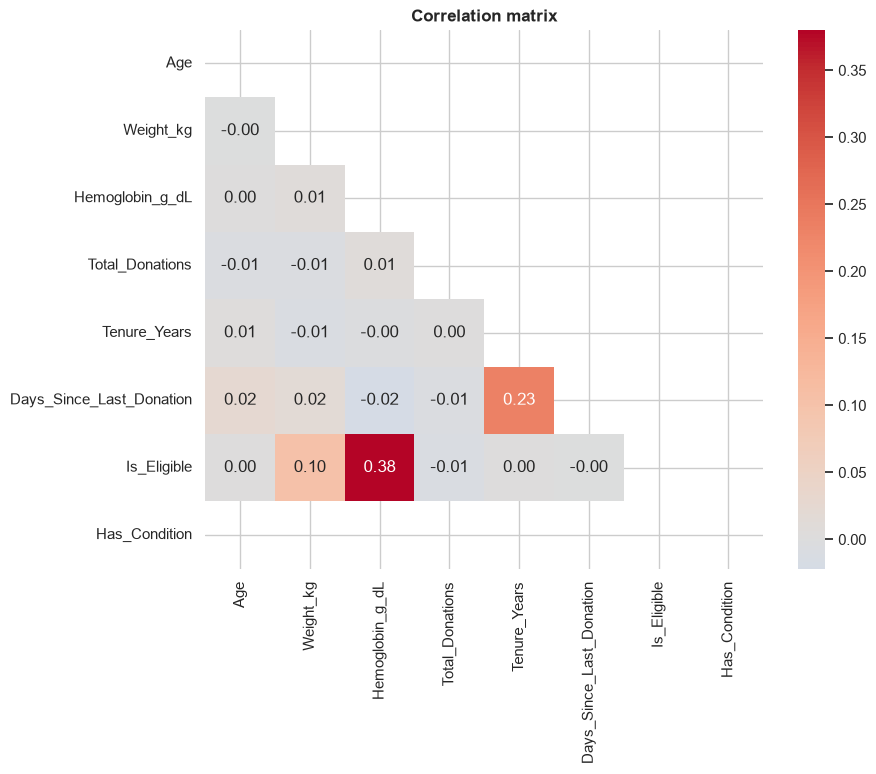

Hemoglobin_g_dL             0.380
Weight_kg                   0.101
Total_Donations            -0.008
Tenure_Years                0.002
Age                         0.001
Days_Since_Last_Donation   -0.000
Has_Condition                 NaN
Name: Is_Eligible, dtype: float64

In [33]:
corr_cols = ['Age', 'Weight_kg', 'Hemoglobin_g_dL', 'Total_Donations', 'Tenure_Years', 'Days_Since_Last_Donation', 'Is_Eligible', 'Has_Condition']
corr = df_clean.assign(Has_Condition=df_clean['Medical_Condition'] != 'None')[corr_cols].astype(float).corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, mask=np.triu(np.ones_like(corr, dtype=bool)))
plt.title('Correlation matrix'); plt.show()
corr['Is_Eligible'].drop('Is_Eligible').sort_values(key=abs, ascending=False).round(3)

The strongest relationships involve eligibility: **medical condition** (strongly negative), **haemoglobin** (positive) and, weakly, **weight** (the 50 kg minimum). Everything else is ≈ 0.

###  Donor-pool segmentation (actionable view)

Segment
Ineligible                         35.8
Eligible – donated in last year    31.7
Eligible – lapsed (>1 year)        28.6
Eligible – never donated            3.9


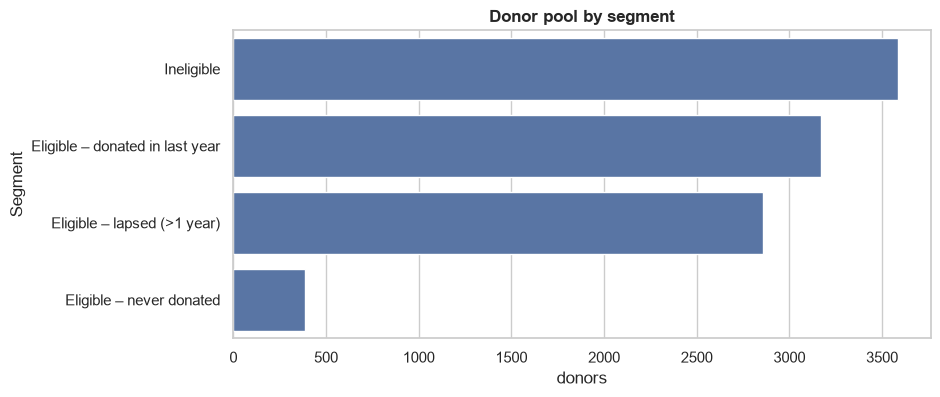


Eligible lapsed + never-donated donors by blood group:


Blood_Group,O+,B+,A+,O-,AB+,A-,B-,AB-
re-engagement pool,1198,1019,582,133,133,80,69,31


In [34]:
d = df_clean.copy()
def segment(r):
    if not r['Is_Eligible']:
        return 'Ineligible'
    if not r['Ever_Donated']:
        return 'Eligible – never donated'
    if r['Days_Since_Last_Donation'] <= 365:
        return 'Eligible – donated in last year'
    return 'Eligible – lapsed (>1 year)'
d['Segment'] = d.apply(segment, axis=1)
seg = d['Segment'].value_counts()
print((seg / len(d) * 100).round(1).to_string())

plt.figure(figsize=(9, 4))
sns.barplot(x=seg.values, y=seg.index, color='#4c72b0')
plt.title('Donor pool by segment'); plt.xlabel('donors'); plt.show()

print('\nEligible lapsed + never-donated donors by blood group:')
pool = d[d['Segment'].isin(['Eligible – lapsed (>1 year)', 'Eligible – never donated'])]
pool['Blood_Group'].value_counts().to_frame('re-engagement pool').T

About **36% of donors are ineligible**. Of the 64% who are eligible, roughly half (≈ 32.5% of all donors) have either never donated or have not donated in over a year – the biggest source of untapped supply.

###  Data-quality recap

In [35]:
q = pd.Series({
    'Invalid / non-Indian-mobile phone numbers': (~df_clean['Contact_Valid']).sum(),
    'Rows sharing an email with another donor': df_clean['Email_Duplicated'].sum(),
    'Last donation before registration date': df_clean['Donated_Before_Registration'].sum(),
    'Weight outliers (IQR)': iqr_flag(df_clean['Weight_kg']).sum(),
    'Hemoglobin outliers (IQR)': iqr_flag(df_clean['Hemoglobin_g_dL']).sum(),
})
q.to_frame('rows').assign(pct=lambda x: (x['rows'] / len(df_clean) * 100).round(2))

,rows,pct
Invalid / non-Indian-mobile phone numbers,5956,59.56
Rows sharing an email with another donor,26,0.26
Last donation before registration date,358,3.58
Weight outliers (IQR),27,0.27
Hemoglobin outliers (IQR),28,0.28


## . Key insights & recommendations

### 5.1 Dataset at a glance
* **10,000 donors × 18 columns** from 20 cities in 15 Indian states, with 10 donation centres. No missing values, no duplicate rows and unique `Donor_ID`s.
* The only apparent "missing" data was a trap: `Medical_Condition = "None"` is a real category, and `Last_Donation_Date = "Never"` is a real state (576 donors who have never donated, all with `Total_Donations = 0`).

### 5.2 Data-quality findings
| # | Finding | Size | Handling |
|---|---|---|---|
| 1 | Phone numbers that are not valid Indian mobiles (not 10 digits or first digit 1–5) | **59.6%** | Flagged (`Contact_Valid`) |
| 2 | Last donation dated *before* the registration date | 358 donors (3.6%) | Flagged |
| 3 | Same email shared by two different donors | 26 rows (13 addresses) | Flagged |
| 4 | Weight / haemoglobin IQR outliers | ≈ 0.3% each | Left unchanged (plausible values) |
| 5 | Constant column `Country` | 100% India | Dropped |
| 6 | Only ~512 distinct names for 10,000 donors | – | Name cannot identify a person |

All emails are `@gmail.com`, and every city maps to exactly one state.

### 5.3 Donor profile
* **Gender:** 49.9% female, 49.1% male, 1.1% other.
* **Age:** 18–65, mean 33.9, median 34. 68% are aged 26–45; only 1.2% are over 55.
* **Weight:** mean 68 kg (45–110). **Haemoglobin:** mean 13.7 g/dL (10–18).
* **Blood group:** O+ (37.3%) and B+ (31.4%) dominate, followed by A+ (18.4%). Rh-negative groups are only ~9.3% in total: O- 4.2%, A- 2.1%, B- 1.9%, **AB- just 1.0%** (101 donors).
* **Geography and centres** are evenly spread (≈ 450–540 donors per city, ≈ 950–1,040 per centre). The blood-group mix does not differ between cities (chi-square p = 0.84).
* **Medical conditions:** 78.1% have none. The most common are hypertension (6.1%), anaemia (4.7%), diabetes (3.9%) and asthma (3.1%).
* **Registrations:** a steady ≈ 920–980 per year from 2015 onward (2025 is partial, to early November). Only 2 donors registered before 2015.

### 5.4 What drives eligibility (the most important finding)
* **64.2% of donors are eligible** (6,416) and 35.8% are not (3,584).
* Eligibility follows a **deterministic rule that matches 100% of records**: *no medical condition* **AND** *haemoglobin ≥ 12.5 g/dL* **AND** *weight ≥ 50 kg*.
* Why the 3,584 donors are ineligible: **2,195 (61%) have a medical condition**; most of the remaining ~1,390 healthy donors are rejected for low haemoglobin (1,145), and 244 more fail only the weight minimum.
* Factors with **no** relationship to eligibility: age group (p = 0.85), state (p = 0.90), donation centre (p = 0.16), blood group (p = 0.07).

### 5.5 Gender gap in haemoglobin and eligibility
* Women's average haemoglobin is **12.98 g/dL vs 14.52 for men** – a 1.54 g/dL gap (Welch t-test, p ≈ 0).
* **29.6% of women are below the 12.5 g/dL cut-off, versus 2.1% of men.**
* As a result, **only 53.4% of women are eligible versus 75.2% of men** (59.3% for the small "Other" group, n = 108).
* Anaemia is the only condition associated with lower haemoglobin (mean 12.86 vs ~13.8 for every other group).

### 5.6 Donation behaviour
* The median donor has made 2 donations; **40.2% have made 0 or 1**, 32.7% have made 3 or more, and only **5.1% are regular donors (5+)**. The maximum is 9.
* Of donors with a donation date, **19.9% donated within the last 90 days, 52.5% within the last year, and 24.6% more than two years ago.**
* Total donations are **uncorrelated with tenure** (Spearman ρ = −0.004), age or eligibility. A donor registered 10 years ago has no more donations than one registered last month – a sign that the history columns are not realistic (likely synthetic data), so don't build loyalty conclusions on them.
* Last-donation dates are spread evenly over the five years (Nov 2020 – Nov 2025): no seasonality.

### 5.6b Donor-pool segmentation
| Segment | Share of donors |
|---|---|
| Ineligible | 35.8% |
| Eligible – donated in the last year | 31.7% |
| Eligible – lapsed (> 1 year) | 28.6% |
| Eligible – never donated | 3.9% |

≈ **3,250 eligible donors (32.5%)** are either lapsed or have never donated. Of these, 1,198 are O+, 1,019 B+, and 133 O-.

### 5.7 Recommendations
1. **Re-engage the ~3,250 eligible-but-inactive donors** first; they need no screening change. Prioritise the 133 O- and 31 AB- donors who are in this pool.
2. **Run an iron/haemoglobin awareness and supplementation programme for women**, the single biggest lever on eligibility (30% of women are below the cut-off). Pre-screening Hb before camps would reduce wasted visits.
3. **Recruit Rh-negative donors**, especially AB-, A-, B- and O-, which together make up under 10% of the base.
4. **Fix contact data** – about 60% of phone numbers are not valid mobile numbers, so outreach to many donors would fail. Add validation at registration, and re-confirm emails that are shared between donors.
5. **Pre-screen on the three eligibility criteria** (condition, Hb ≥ 12.5, weight ≥ 50 kg) at sign-up and track the *reason* for deferral instead of only Yes/No.
6. **Validate date logic** in the registration system so a donation can't predate registration.

### 5.8 Caveats
* The near-perfectly uniform distributions (cities, centres, years, blood group independent of city) and the lack of any relationship between donation counts and tenure strongly suggest **synthetic data**; be cautious about generalising to real donor populations.
* "Today" was assumed to be **7 Nov 2025**, the latest date in the file; recency figures depend on this.
* Eligibility is only a snapshot flag; the dataset does not record deferral reasons or deferral duration.
